# Tile Coordinates

Cuts each image in `data/` into 256x256 tiles (same grid as `scripts/dataset.py`) and gets the longitude/latitude of each tile from the GeoTIFF.

One row per tile:
- `west`, `south`, `east`, `north`: tile bounding box
- `center_lon`, `center_lat`: tile center
- `row`, `col`: top-left pixel of the tile in its image

In [5]:
import math
import sys

import pandas as pd
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt

sys.path.append("../scripts")
from dataset import DATA_DIR, TILE, SPLITS

STRIDE = TILE  # 256 = no overlap, 128 = half overlap (like train)

## Coordinates for each tile

In [6]:
def get_split(i):
    if i in SPLITS["train"]:
        return "train"
    if i in SPLITS["val"]:
        return "val"
    return "test"


def tile_coordinates(i):
    src = rasterio.open(DATA_DIR / f"image_{i}" / "image.tif")

    # Top-left pixel of every tile
    rows = []
    for r in range(0, src.height - TILE, STRIDE):
        rows.append(r)
    rows.append(src.height - TILE)

    cols = []
    for c in range(0, src.width - TILE, STRIDE):
        cols.append(c)
    cols.append(src.width - TILE)

    out = []
    for r in rows:
        for c in cols:
            window = Window(c, r, TILE, TILE)
            west, south, east, north = src.window_bounds(window)
            tile = {
                "image": i,
                "split": get_split(i),
                "row": r,
                "col": c,
                "west": west,
                "south": south,
                "east": east,
                "north": north,
                "center_lon": (west + east) / 2,
                "center_lat": (south + north) / 2,
            }
            out.append(tile)

    src.close()
    return pd.DataFrame(out)


tables = []
for i in range(1, 13):
    tables.append(tile_coordinates(i))
tiles = pd.concat(tables, ignore_index=True)

print(len(tiles), "tiles")
tiles.head()

971 tiles


,image,split,row,col,west,south,east,north,center_lon,center_lat
0,1,train,0,0,-95.818103,29.592379,-95.813752,29.59673,-95.815928,29.594554
1,1,train,0,256,-95.813752,29.592379,-95.809401,29.59673,-95.811577,29.594554
2,1,train,0,512,-95.809401,29.592379,-95.805050,29.59673,-95.807225,29.594554
3,1,train,0,768,-95.805050,29.592379,-95.800699,29.59673,-95.802874,29.594554
4,1,train,0,1024,-95.800699,29.592379,-95.796347,29.59673,-95.798523,29.594554


## Quadkey for each tile

The building download list (`data/buildings/dataset-links.csv`) is organized by quadkey at zoom level 9. A quadkey is a 9-digit code naming one square of the world map, so we turn each tile's center into one.

In [7]:
ZOOM = 9


def get_quadkey(lon, lat):
    n = 2 ** ZOOM  # squares across the world at this zoom

    # Which column and row of the world grid the point is in
    x = int((lon + 180) / 360 * n)
    lat_rad = math.radians(lat)
    y = int((1 - math.asinh(math.tan(lat_rad)) / math.pi) / 2 * n)

    # Build the code one digit at a time, from the biggest square to the smallest
    quadkey = ""
    for level in range(ZOOM, 0, -1):
        bit = 1 << (level - 1)
        digit = 0
        if x & bit:
            digit = digit + 1
        if y & bit:
            digit = digit + 2
        quadkey = quadkey + str(digit)
    return quadkey


quadkeys = []
for t in tiles.itertuples():
    quadkeys.append(get_quadkey(t.center_lon, t.center_lat))
tiles["quadkey"] = quadkeys

tiles.groupby("image").quadkey.unique()

image
1                [023130133]
2                [023131200]
3                [023130133]
4                [023131023]
5                [023131023]
6                [023131023]
7                [023131023]
8     [023131022, 023131023]
9     [023131022, 023131023]
10               [023131023]
11               [023131023]
12               [023131022]
Name: quadkey, dtype: object

## Draw it out

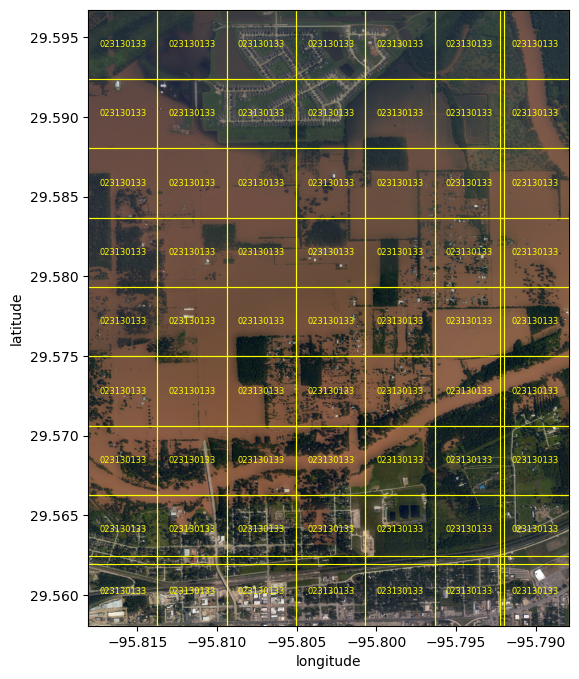

In [8]:
i = 1
with rasterio.open(DATA_DIR / f"image_{i}" / "image.tif") as src:
    img = src.read([1, 2, 3]).transpose(1, 2, 0)
    left, bottom, right, top = src.bounds

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img, extent=(left, right, bottom, top))
for t in tiles[tiles.image == i].itertuples():
    ax.plot([t.west, t.east, t.east, t.west, t.west],
            [t.south, t.south, t.north, t.north, t.south], color="yellow", lw=0.8)
    ax.text(t.center_lon, t.center_lat, t.quadkey, color="yellow", ha="center", va="center", fontsize=6)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
plt.show()